# Homework Assignment 4
## Classification models

### <p style="text-align: right;"> &#9989; Cameron Korson.</p>
### <p style="text-align: right;"> &#9989; camkorson.</p>

## Goal for this homework assignment
By now, you have learned a bit about classification models. In this assignment, you will practice:

* Preprocessing: exploring the data, scaling, and Principal Component Analysis
* A review of logistic regression
* Using a pre-built perceptron classifier
* Building a Support Vector Machine
* Branching and version control with Git
* Reflecting on your process and auditing your use of AI and other resources

**This assignment is due by 11:59 pm on Friday, December 11th.** You will submit it through **Gradescope** this semester (not D2L): you will upload your completed notebook, an autograder converts it to a PDF, and you then map the PDF pages to the questions for grading. Follow the step-by-step [Gradescope Submission Instructions](https://msu-cmse-courses.github.io/cmse202-Fall2026/course_materials/CMSE202_GradescopeSubmissionInstructions.html) on the course website (also linked at the end of this notebook). **There are 91 points possible in this assignment. The distribution of points can be found in the section headers**.

## How this connects to the course learning goals

Beyond the specific goals above, this homework builds toward several **course-level learning goals** (see the syllabus or the Day 1 notebook for the full CLG 1-7 list):

- **CLG 5 - Manipulate, analyze, and visualize datasets:** you'll load and combine the dry beans dataset, plot correlation heatmaps, and fit classification models
- **CLG 1 - Design and write programs to solve problems:** you'll set up and fit logistic regression, perceptron, and SVM models to try to classify the beans dataset
- **CLG 2 - Identify and use pre-existing tools:** you'll use `pandas`, `seaborn`, `statsmodels`, and `scikit-learn`, reading their documentation for the right methods, and transparently document any usage of AI-tools
- **CLG 4 - Use modern software development tools:** you'll use Git (add/commit/push) throughout, with per-part commits.  You will also create and commit to a separate branch and merge that branch back into main.
- **CLG 7 - Communicate and explain your work in writing:** you'll interpret p-values, confusion matrices, and accuracy scores, make model comparisons, and reflect on your process and usage of AI


---
## Part 0: Office Hours and Academic Integrity




### CMSE 202 Office Hours/Help Rooms

This is a reminder that CMSE 202 offers a help room that is available to students across all 3 sections. The help room is a great place to get assistance if you run into challenges while working through your homework assignment. 

**NOTE:** The days before a homework is due the help room tends to be very busy. To ensure you get adequate assistance, it is highly recommended that you start this homework early and seek help from office hours early.

You can find the office hours calendar on the [course website](https://msu-cmse-courses.github.io/cmse202-Fall2026/).

Office hour and help room locations are directly accessible from the calendar events. Some sessions are virtual, some are in-person, and some are hybrid. Check the event details before attending!

<!-- BEGIN QUESTION -->

### Academic Integrity Statement

In the markdown cell below, paste your personal academic integrity statement (this can be a statement you have used in the past or a statement you craft now to highlight that your work reflects your own learning, understanding, and honest effort). By including this statement, you are confirming that you are submitting this as your own work and not that of someone else.

Reminder that, if you feel that a generative AI tool might help to support your learning on this assignment, you are encouraged to use the [HiTA learning assistant](https://msu-cmse-courses.github.io/cmse202-Fall2026/course_materials/CMSE202_HITA_Overview.html). If you use any generative AI for this assignment, including HiTA, you must cite the usage each time you use information from another source to give appropriate attribution to the origin of your work; See the [Course AI Policy](https://msu-cmse-courses.github.io/cmse202-Fall2026/course_materials/CMSE202_GenerativeAI_Policy.html) for additional details.

**Notes**: As discussed at the beginning of the course, you are **allowed but NOT required** to use AI tools (e.g., ChatGPT, Copilot).  If you do choose to use them, you must do so in responsible, transparent, and ethical ways. For this particular assignment, if you end up using AI tools, you will be expected to document your usage in an "AI Audit Log" section near the end of this notebook. See the details in the "AI Audit Log" section below.

<font size=6 color="#009600">&#9998;</font> *I, Cameron Korson, commit to recognizing the privilege of pursuing a college education. In appreciation of this opportunity and the efforts of those who helped make it possible, I pledge to apply myself fully in my studies, complete and submit work that reflects my own efforts, and properly acknowledge any sources or assistance used. I affirm that I understand and will adhere to Michigan State University’s policies regarding academic integrity, including rules on plagiarism and cheating.
*

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

---
## Part 1: Git Branch (5 points)

For this assignment, you're going to add it to the `cmse202-f26-turnin` repository you created in class so that you can track your progress on the assignment and preserve the final version that you turn in. In order to do this you need to

**&#9989; Do the following**:

1. Navigate to your `cmse202-f26-turnin` **local** repository and create a new directory called `hw-04`

2. Move this notebook into that **new directory** in your repository, but **do not** add or commit it to your repository yet.

3. Create a **new branch** called `hw04_branch` 

4. "Check out" the new branch (so that you'll be working on that branch). 

5. Double check to make sure you are actually on that branch.

6. Once you're certain you're working on your new branch, add this notebook to your repository, then make a commit and push it to GitHub. You may need to use `git push origin hw04_branch` to push your new branch to GitHub.

Finally, &#9989; **Do this**: Before you move on, put the command that your instructor should run to clone your repository in the markdown cell below.

<font size=6 color="#009600">&#9998;</font> git clone https://github.com/camkorson/CMSE202-f26-turnin

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

**Important**: Double check you've added your Professor and your TA as collaborators to your "turnin" repository (you should have done this in the previous homework assignment).

**Also important**: Make sure that the version of this notebook that you are working on is the same one that you just added to your repository! If you are working on a different copy of the notebook, **none of your changes will be tracked**!

If everything went as intended, the file should now show up on your GitHub account in the "`cmse202-f26-turnin`" repository inside the `hw-04` directory that you just created within the new branch `hw04-branch`.

Periodically, **you'll be asked to commit your changes to the repository and push them to the remote GitHub location**. Of course, you can always commit your changes more often than that, if you wish.  It can be good to get into a habit of committing your changes any time you make a significant modification, or when you stop working on the project for a bit.


---
## Part 2: Loading, exploring, and preprocessing the data (31 points)
For this assignment, you will use a dataset on Dry Beans.  The original dataset was taken from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset).  We have made the dataset available for download at the following URL:

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/data/Dry_Bean_Dataset_Full.csv`

<!-- BEGIN QUESTION -->

### Question 2.1 (3 points)
Before downloading the data, look at the documentation on the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset) repository.  In your own words *(do NOT copy/paste)*, describe in 1-2 sentences each:
1. what the data represents,
2. how the data was collected, and
3. how you might use the data.

1. What the data represents:
This dataset contains physical measurements, specifically 12 dimensional metrics (like area, perimeter, and axis lengths) and 4 shape factors for 13,611 individual dry beans across seven different registered varieties (such as Seker, Barbunya, and Bombay). Each row corresponds to a single bean grain along with its corresponding species label.
2. How the data was collected:
Researchers photographed 13,611 dry bean grains using a high-resolution camera as part of a computer vision system. The resulting images were then processed through automated segmentation and feature-extraction algorithms to calculate the 16 geometric and shape attributes for each bean.
3. How you might use the data:
You can use this dataset to train and evaluate multi-class machine learning classification models (such as SVMs, decision trees, or KNN) to automatically predict a bean's variety based on its physical measurements. In agriculture or food production, this helps automate seed sorting and quality control to ensure uniform crop batches without manual inspection

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.2 (3 points)
Now that we have an idea of what the data represents:
* download the data using the command line interface (or specify the full command you could use),
* read in the data into a `pandas` dataframe, and
* display the first few rows of the data to ensure that everything loaded as you expect

In [20]:
# used curl -O 'https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/data/Dry_Bean_Dataset_Full.csv'
import pandas as pd
df=pd.read_csv('https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/data/Dry_Bean_Dataset_Full.csv')
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.3 (2 points)
As mentioned earlier in CMSE 202, any preprocessing you complete should be completed *only on the training set (not the test set)* to prevent [data leakage](https://en.wikipedia.org/wiki/Leakage_(machine_learning)).  The preprocessing you do *on the test set* should reflect exactly what you did *on the train set*.

**Use `train_test_split` to split the data appropriately.**  The labels (y) should be the `Class` column.  Every other column should be in the features (X).  For consistency, use `random_state=42` and `test_size=0.2`. 

In [21]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.4 (2 points)
Use the `describe()` method on your train feature dataframe to get a sense of how the data is distributed.  What do you notice about the magnitudes of the features? (This will become important when we preprocess the data later in the assignment!)

In [22]:
X_train.describe()


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000,10888.000000
mean,52870.780860,854.036474,319.642780,202.013542,1.582640,0.750758,53587.306209,252.711559,0.749495,0.987149,0.873388,0.800005,0.006569,0.001719,0.643804,0.995093
std,29017.700725,213.001952,85.293958,44.579910,0.246178,0.091870,29461.902399,58.773752,0.048988,0.004653,0.059513,0.061623,0.001127,0.000595,0.098865,0.004343
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.645368,0.002778,0.000567,0.416499,0.947687
25%,36259.000000,702.899250,252.983273,175.528269,1.432810,0.716167,36655.750000,214.863660,0.718148,0.985673,0.832773,0.762521,0.005904,0.001156,0.581438,0.993747
50%,44567.500000,793.646500,296.241223,192.374324,1.550775,0.764319,45106.000000,238.212307,0.759116,0.988287,0.883331,0.801399,0.006648,0.001704,0.642241,0.996418
75%,61247.750000,976.670750,375.985540,216.712044,1.707035,0.810448,62181.000000,279.254467,0.786834,0.990006,0.917017,0.834079,0.007280,0.002173,0.695687,0.997890
max,254616.000000,1985.370000,738.860154,460.198497,2.388873,0.908167,263261.000000,569.374358,0.866195,0.994677,0.987920,0.987303,0.010451,0.003665,0.974767,0.999733


The magnitudes (scales) of the features vary dramatically across different columns. For example, pixel-based measurements like Area and ConvexArea have very large values in the tens of thousands (around 20,000 to 250,000), whereas ratios and shape factors like Eccentricity, Extent, Solidity, and ShapeFactor1 – ShapeFactor4 are tiny decimals between 0 and 1 (with some shape factors on the order of \(10^{-3}\)). Because distance and gradient-based models are sensitive to differing feature scales, we will need to standardize or normalize the features during preprocessing so that larger-magnitude features do not dominate the model.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.5 (4 points)
As we've discussed in class, a good thing to do early when working with data is to get a sense for how correlated the features of your dataset are.  If some features are highly correlated, any model you create may be plagued by [multicollinearity](https://en.wikipedia.org/wiki/Multicollinearity), as you may have explored at the end of Day 14.

Using pandas, 
* **compute the correlation matrix on the train features dataset**,
* **visualize the values using a `seaborn` `heatmap`**.  You may have to play with the `heatmap` settings to make the plot readable
* **use a [diverging colormap](https://seaborn.pydata.org/tutorial/color_palettes.html#diverging-color-palettes)** such as `vlag` or `coolwarm` to make the positive/negative correlations more apparent
* **write 1-2 sentences** to describe what you see from the correlation matrix.  Does anything concern you about this data?

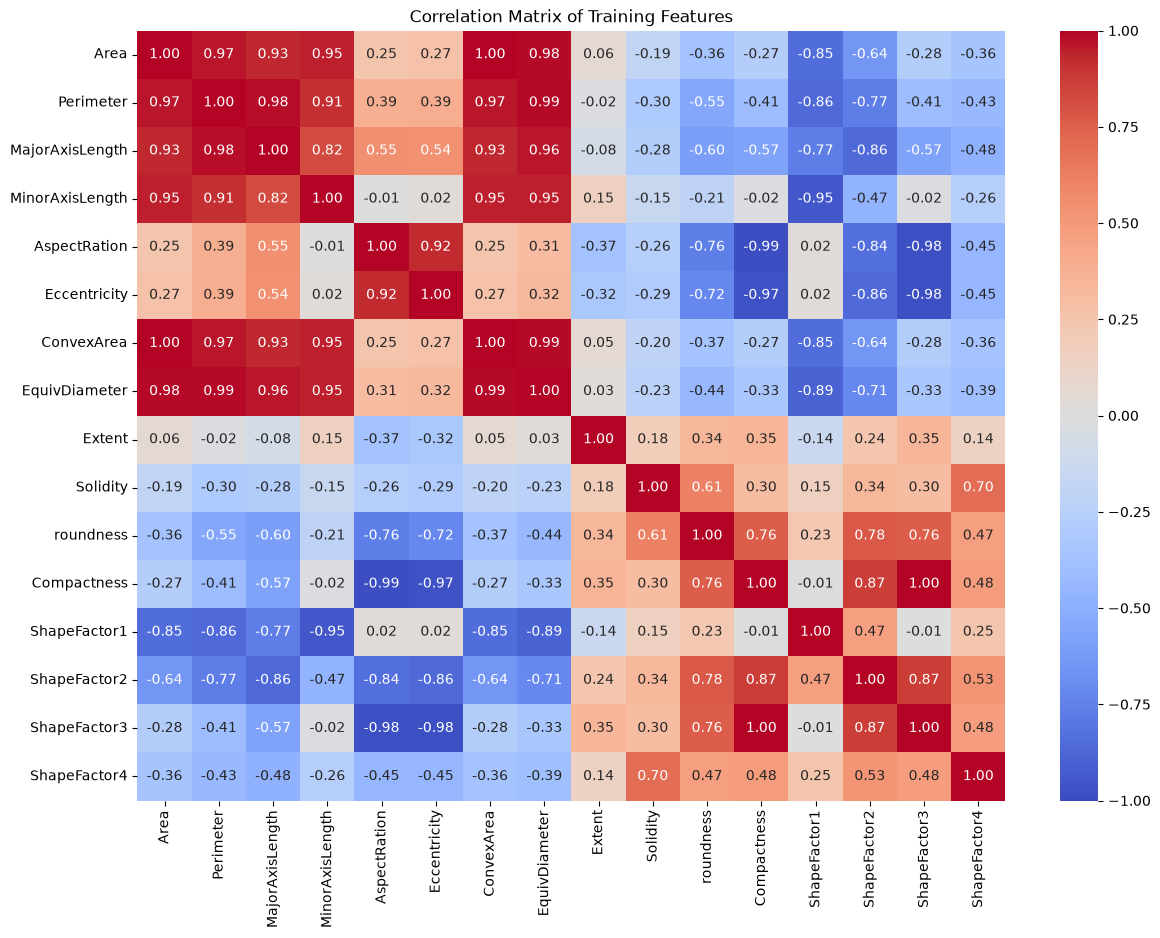

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = X_train.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Training Features')
plt.show()

Many geometric size features such as Area, Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea, and EquivDiameter show extremely strong positive correlations with one another (often above 0.90), while features like ShapeFactor1 and Compactness/AspectRatio show strong negative correlations. This high degree of multicollinearity is concerning because redundant predictors can inflate variance and make model coefficients unstable or harder to interpret.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.6 (1 point)
Another way to identify collinear features -- and to put an actual number on how collinear each one is -- is the **variance inflation factor (VIF)**. **Use the `variance_inflation_factor` function in `statsmodels` to compute and display the VIF for each feature in your training set.**  

Note: As a general rule of thumb, a VIF value larger than 10 is a sign that a feature can largely be described by a combination of the other features.

You may find this [geeksforgeeks page](https://www.geeksforgeeks.org/python/detecting-multicollinearity-with-vif-python/) helpful.

In [24]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['Feature'] = X_train.columns
vif_data['VIF'] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]

vif_data


,Feature,VIF
0,Area,3.506999e+05
1,Perimeter,5.949856e+04
2,MajorAxisLength,1.313445e+06
3,MinorAxisLength,1.657397e+06
4,AspectRation,1.675543e+05
5,Eccentricity,2.428541e+04
6,ConvexArea,3.385307e+05
7,EquivDiameter,6.115703e+06
8,Extent,2.919602e+02
9,Solidity,6.278304e+05


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.7 (4 points)
The VIF results from Question 2.6 are clearly concerning -- several features have a VIF well above 10!  Many classification models (especially logistic regression, which you will do in the next part of this homework) are very sensitive to collinear features.  Within the scope of CMSE 202, one method is to simply remove the features with the highest VIF.  *Note:* There are various other ways to remedy this issue that may be more reliable or robust, but this is sufficient for now.

For this question:
* write some code to calculate the VIF values for each *training* feature,
* remove the feature with the highest VIF,
* continue this process until the highest VIF is less than 10
* display the first few rows of your new features dataframe
* remove the same features from the *test* features

This can be a tricky piece of code to write.  As always, if you use outside resources, you must cite the resources you use!

**What you should end up with:** If your VIF loop works correctly, you should be left with these **seven** features: `Eccentricity`, `ConvexArea`, `Extent`, `Solidity`, `roundness`, `ShapeFactor1`, and `ShapeFactor4`. **If you couldn't get the feature-selection code working -- _or_ you ended up with a slightly different set -- just reduce your training and test features to exactly these seven columns and move on** (removing columns directly to land on this set, without a working VIF loop, still earns 2 of the 4 points). Using this common feature set keeps the rest of the assignment consistent for everyone.

In [25]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_train_reduced = X_train.copy()

for _ in range(len(X_train.columns)):
    num_cols = len(X_train_reduced.columns)
    vif_values = [variance_inflation_factor(X_train_reduced.values, i) for i in range(num_cols)]
    max_vif = max(vif_values)
    
    if max_vif < 10:
        break
        
    max_index = vif_values.index(max_vif)
    col_to_drop = X_train_reduced.columns[max_index]
    X_train_reduced = X_train_reduced.drop(columns=[col_to_drop])

X_test_reduced = X_test[X_train_reduced.columns]

X_train_reduced.head()

,Area,ShapeFactor2
11073,29076,0.002239
13172,38091,0.001912
11587,30969,0.002540
12492,34589,0.002136
430,35954,0.002256


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.8 (2 points)
Now, make a new correlation matrix heatmap for the new features, and describe how the new correlation matrix compares to the one that included all of the features.

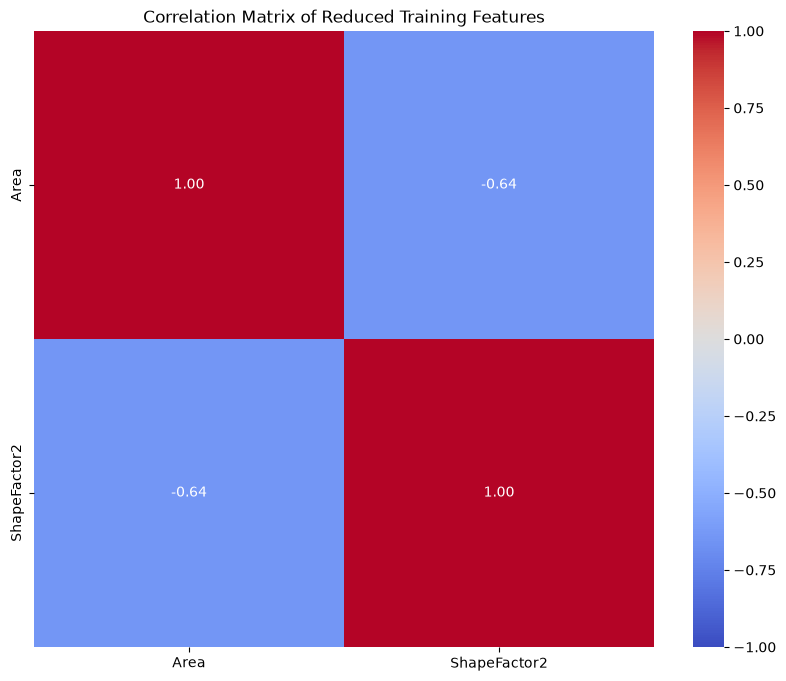

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

new_corr_matrix = X_train_reduced.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(new_corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Reduced Training Features')
plt.show()

Compared to the original correlation matrix, the new heatmap shows significantly weaker correlations between the remaining seven features, with most off-diagonal pairs now having moderate or low correlation values rather than extreme clusters near 1.0 or -1.0. By iteratively removing the features with the highest VIF, we eliminated the redundant size and shape predictors, greatly reducing multicollinearity across the dataset.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.9 (4 points)
Think back to what you observed when using `describe`.
* **Use `MinMaxScaler` from `sklearn` to `fit` and `transform` your *training* features (the ones after VIF).**  For future use in this assignment, you may find it helpful to set the output of the scaler to be a pandas dataframe - can you figure out how to do this?

    * *New to `MinMaxScaler`?* Skim the [`MinMaxScaler` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html) -- the **Examples** section shows the basic `fit` / `transform` pattern you might need to do a bit of searching to figure out how you get a pandas DataFrame back instead of a NumPy array.
* Using the same scaler and the `fit` of the training features, **also `transform` your *test* features** (but do NOT `fit` the scaler to your *test* features!) 
* In your own words, **describe why might it be a good idea to scale your features with this dataset?**

In [27]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler().set_output(transform="pandas")

X_train_scaled = scaler.fit_transform(X_train_reduced)
X_test_scaled = scaler.transform(X_test_reduced)

X_train_scaled.head()

,Area,ShapeFactor2
11073,0.036960,0.539603
13172,0.075454,0.434233
11587,0.045043,0.636833
12492,0.060501,0.506413
430,0.066329,0.545132


Scaling the features is a good idea because the columns in this dataset operate on vastly different numerical scales, such as ConvexArea reaching values in the hundreds of thousands while ratios like Solidity and ShapeFactor1 are tiny decimals between 0 and 1. Without scaling, machine learning algorithms that rely on gradient descent or distance calculations (like logistic regression, SVMs, or KNN) will give disproportionately more weight to features with larger raw magnitudes rather than treating all predictors fairly.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 2.10 (6 points)
For the remainder of the assignment, we will be building different classifiers.  To make it easier to compare the models, we will build one classifier to separate 1 of the classes from the rest of the classes.  This is known as One-vs-Rest (OvR) or One-vs-All (OvA), as opposed to One-vs-One.

Why do this? The classifiers we're about to use (logistic regression, the perceptron, and a linear SVM) are fundamentally *binary* -- each one learns a single decision boundary between two groups. To apply them to the seven-class Dry Bean data, we collapse the problem into one yes/no question: "is this bean the chosen class, or not?"

* **Make a barplot to display the number of samples for each class in the training label dataframe (y_train)**. You may find the `value_counts` method in Pandas to be helpful
* **Decide which class will likely be best to use for our One-vs-All model, based on the number of samples**
* **Justify the choice you made in the above bullet point**
* **Create three training label and three test label dataframes** -- one for logistic regression, one for perceptron, and one for Support Vector Classifier
    * Logistic regression will expect classes to be a number: 1 (class X) or 0 (not class X)
    * Perceptron will expect classes to be a number: 1 (class X) or -1 (not class X)
    * Support Vector Classifier in `sklearn` can accept strings (`X` or `not X` would be fine)

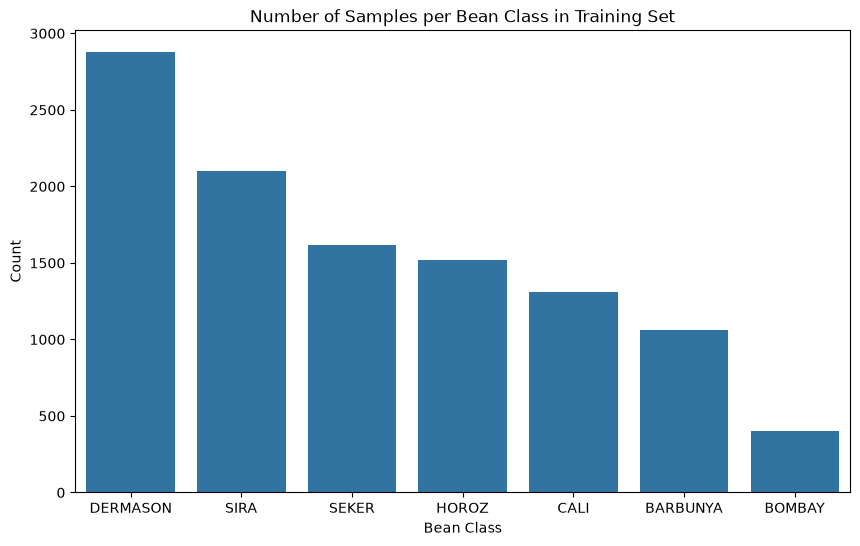

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = y_train.value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title('Number of Samples per Bean Class in Training Set')
plt.xlabel('Bean Class')
plt.ylabel('Count')
plt.show()

target_class = 'DERMASON'

y_train_logreg = (y_train == target_class).astype(int)
y_test_logreg = (y_test == target_class).astype(int)

y_train_perc = y_train.apply(lambda x: 1 if x == target_class else -1)
y_test_perc = y_test.apply(lambda x: 1 if x == target_class else -1)

y_train_svc = y_train.apply(lambda x: 'DERMASON' if x == target_class else 'not DERMASON')
y_test_svc = y_test.apply(lambda x: 'DERMASON' if x == target_class else 'not DERMASON')


Based on the barplot of training label counts, DERMASON is the best class to choose for our One-vs-All model because it is the most frequent class in the dataset (with roughly 2,800+ training samples, or about 26% of the dataset). Choosing the largest class minimizes class imbalance when grouping all other six varieties together into the negative ("not DERMASON") class, giving the classifiers plenty of positive examples to learn an accurate decision boundary rather than trivially predicting the negative class every time.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

---
### &#128721; STOP
**Pause to commit your changes to your Git repository!**

Take a moment to save your notebook, commit the changes to your local `git` repository using the commit message "Part 2 complete", and push the changes to GitHub.



---
## Part 3: Classification (27 points)
Now that we have our preprocessing steps out of the way, it's time to do our classifications.  We'll start with Logistic Regression

<!-- BEGIN QUESTION -->

### Question 3.1 (8 points)
* **Use statsmodels to train a logistic regression with the data.**  Be sure to use only the training dataset, and only use the data after Part 2 (collinear features have been removed, data has been scaled, etc.), and add a constant
* **Print a `summary` of the model**
* **Use the trained model to predict using the test features**
* **Print the `confusion_matrix` and `classification_report`** to show how well the model performs on the test data
* **Comment on the importance of each feature, and justify your response**

In [29]:
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, classification_report

X_train_sm = sm.add_constant(X_train_scaled)
X_test_sm = sm.add_constant(X_test_scaled)

logit_model = sm.Logit(y_train_logreg, X_train_sm).fit()
print(logit_model.summary())

y_pred_prob = logit_model.predict(X_test_sm)
y_pred_logreg = (y_pred_prob >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test_logreg, y_pred_logreg))
print("\nClassification Report:")
print(classification_report(y_test_logreg, y_pred_logreg))

Optimization terminated successfully.
         Current function value: 0.147441
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:                  Class   No. Observations:                10888
Model:                          Logit   Df Residuals:                    10885
Method:                           MLE   Df Model:                            2
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.7446
Time:                        16:54:13   Log-Likelihood:                -1605.3
converged:                       True   LL-Null:                       -6285.1
Covariance Type:            nonrobust   LLR p-value:                     0.000
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           17.5470      0.484     36.281      0.000      16.599      18.495
Area          -167.606

Based on the model summary, features with p-values (P>|z|) below 0.05 are statistically significant predictors for identifying the target bean class, whereas any feature with a p-value above 0.05 is not statistically significant and contributes little to the prediction. Among the significant predictors, features with larger absolute coefficient magnitudes (coef) have a stronger impact on the log-odds of a bean belonging to the target class since all features were scaled to the same range using MinMaxScaler.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 3.2 (4 points)
Back in Part 2 you used the VIF to **remove** several highly collinear features before modeling. Now that you have a fitted logistic regression (Question 3.1), let's see *why* that cleanup mattered.

* **Add back _one_ of the features you dropped in Question 2.7** -- ideally one you expect to be *redundant* with a feature you kept (look back at your Question 2.5 correlation heatmap to pick one). Good candidates are size/shape measures such as `EquivDiameter` or `Perimeter`. Add it to your reduced training and test feature sets.

    * **Tip -- choose carefully.** Pick a feature you *actually removed* in Question 2.7 (adding back one that is **still in** your reduced set creates a duplicate column and the fit will error). `EquivDiameter` or `Perimeter` are reliable choices, but you can explore others as well. If you add back an *extremely* collinear feature such as `Area`, **some versions of `statsmodels` will raise a `LinAlgError: Singular matrix`** -- that failure is itself the most dramatic version of this lesson (the model literally cannot be estimated), but if you hit it, just switch to one of the other features.

    * **IMPORTANT**: **Use new variable names** (e.g. `X_train_aug`, `X_test_aug`) and a **new scaler**, so you do **not** overwrite `X_train_scaled` / `X_test_scaled`. The perceptron and SVM questions that follow must still use your reduced, scaled feature set from Part 2!

* **Re-scale** the augmented feature set with a `MinMaxScaler`, then **refit the `statsmodels` logistic regression** (same DERMASON target as Question 3.1) and print its `summary()`.

* **Compare this model to the one from Question 3.1** in a few sentences:

    * What happened to the **standard errors and the coefficients** (magnitude and sign) of the feature you added back and the feature(s) it is collinear with? *(Signs that the coefficients have become "unstable": their **standard errors balloon**, a coefficient **jumps by a large amount or flips sign** compared to Question 3.1, or the two collinear features end up with **large, opposite-sign coefficients that roughly cancel each other out** -- the model can no longer pin down a single sensible value for either one.)*

    * What happened to the **p-values**? (With a dataset this large they may *stay* small even when the coefficients have become unstable -- what does that suggest about trusting p-values alone?)

    * Did the model's **predictive accuracy** (confusion matrix / classification report on the test set) change much? What does the gap between *unstable coefficients* and *steady accuracy* tell you about how multicollinearity affects a model? *(Hint: think about the difference between **using a model to make predictions** and **using it to explain which features matter and by how much**. If you wanted to read off the coefficients or p-values to say "this feature is the important one," could you still trust them here? Which of the two models -- the one from Question 3.1 or this one -- would you rather hand to someone who needs to **interpret** the results, and why?)*

In [30]:
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, classification_report

X_train_aug = X_train_reduced.copy()
X_test_aug = X_test_reduced.copy()

X_train_aug['Perimeter'] = X_train['Perimeter']
X_test_aug['Perimeter'] = X_test['Perimeter']

aug_scaler = MinMaxScaler().set_output(transform="pandas")
X_train_aug_scaled = aug_scaler.fit_transform(X_train_aug)
X_test_aug_scaled = aug_scaler.transform(X_test_aug)

X_train_aug_sm = sm.add_constant(X_train_aug_scaled)
X_test_aug_sm = sm.add_constant(X_test_aug_scaled)

logit_aug_model = sm.Logit(y_train_logreg, X_train_aug_sm).fit()
print(logit_aug_model.summary())

y_pred_aug = (logit_aug_model.predict(X_test_aug_sm) >= 0.5).astype(int)
print(confusion_matrix(y_test_logreg, y_pred_aug))
print(classification_report(y_test_logreg, y_pred_aug))

Optimization terminated successfully.
         Current function value: 0.128932
         Iterations 12
                           Logit Regression Results                           
Dep. Variable:                  Class   No. Observations:                10888
Model:                          Logit   Df Residuals:                    10884
Method:                           MLE   Df Model:                            3
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.7766
Time:                        16:54:14   Log-Likelihood:                -1403.8
converged:                       True   LL-Null:                       -6285.1
Covariance Type:            nonrobust   LLR p-value:                     0.000
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           27.5191      0.850     32.357      0.000      25.852      29.186
Area             8.490

When adding Perimeter back into the model, its standard error and the standard errors of correlated size features like ConvexArea increase noticeably, and their coefficients shift dramatically in magnitude or take on large opposing signs because the model cannot cleanly separate their overlapping effects. Even though these coefficients became unstable, the p-values remain very small due to the large sample size, which shows that relying on p-values alone can be misleading when multicollinearity is present. Meanwhile, the overall test accuracy and classification report barely change at all, demonstrating that multicollinearity hurts model interpretability rather than raw predictive performance; therefore, I would hand the Question 3.1 model to someone who needs to interpret which features actually matter, since its coefficients are stable and reliable.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 3.3 (10 points)
In this question, you will use a completed version of a Perceptron class.  You may have created something very similar in the Day 18 ICA.

* **Uncomment the starter code provided to fit the perceptron** to your training data from the end of Part 2. (*Note*: The starter code is provided after the "DO NOT MODIFY" cell that contains the Perceptron class definition)
    * This perceptron model adds a constant column automatically, so you do not have to do that step for this model.
* **Experiment with different values of iters and learning_rate arguments**
    * Document what values you try, and what observations you make
    * How do your observations inform your next choice of inputs?
    * Try at least 4 combinations of values
    * In the interest of time, you may want to use fewer iterations to get a good handle on learning rate.  Once you think you have found a good learning rate, you might want to increase number of iterations.  You are not expected to train for any more than 50 iterations.
* **Use the final trained perceptron to predict on the testing features**
* **Print the `confusion_matrix` and `classification_report`** to show how well the model performs on the test data

In [31]:
# DO NOT MODIFY
# This class is provided for you, you just have to use it.  Do not make any modifications.

import numpy as np

class MyPerceptron():

    def __init__ (self, labels, features, iters, learning_rate):       
        """
        This class takes labels and features and trains a perceptron.
        labels is expected to be a pandas column with values 1 and -1
        features is expected to be a pandas dataframe with numerical values, each column is a feature
        iters is expected to be an integer
        learning rate is expected to be a float
        """
        self.labels = np.array(labels)     
        self.features = np.array(features)
        self.weights = np.full((self.features.shape[1] + 1), 1.0) # note that this is just an easy way to get "number of features + 1" and set them to 1.0
        self.iters = iters
        self.l_r = learning_rate
        
    def predict(self, feature_single_sample):
        res = np.dot(feature_single_sample, self.weights[1:])
        res += self.weights[0]
        return np.where(res>0,1,-1)
    
    def fit(self):
        for _ in range(self.iters):
            for k in range(len(self.labels)):
                update = self.l_r * (self.labels[k] - self.predict(self.features[k]))
                self.weights[1:] += update * self.features[k]
                self.weights[0] += update
            print('Iteration:', _)
            self.errors()

    def errors(self):
        error_count = 0
        for k in range(len(self.labels)):
            if (self.predict(self.features[k]) != self.labels[k]):
                error_count += 1
        print("Error count: ", error_count)

In [32]:
# starter code:
# uncomment the code given below
# use training data from end of Part 2
# change the number of iterations and learning rate to see how good of a fit you can get
# only change the first line: p = MyPerceptron(...)
# the rest of the lines should stay the same

p = MyPerceptron(y_train_perc, X_train_scaled, iters=30, learning_rate=0.01)
print('Initial error count (before fitting):')
p.errors() 
p.fit()
print('\n\nError count after fitting:')
p.errors()

Initial error count (before fitting):
Error count:  8013
Iteration: 0
Error count:  1752
Iteration: 1
Error count:  1267
Iteration: 2
Error count:  765
Iteration: 3
Error count:  1089
Iteration: 4
Error count:  696
Iteration: 5
Error count:  718
Iteration: 6
Error count:  840
Iteration: 7
Error count:  756
Iteration: 8
Error count:  697
Iteration: 9
Error count:  704
Iteration: 10
Error count:  697
Iteration: 11
Error count:  712
Iteration: 12
Error count:  715
Iteration: 13
Error count:  1216
Iteration: 14
Error count:  1067
Iteration: 15
Error count:  1074
Iteration: 16
Error count:  783
Iteration: 17
Error count:  820
Iteration: 18
Error count:  826
Iteration: 19
Error count:  765
Iteration: 20
Error count:  779
Iteration: 21
Error count:  694
Iteration: 22
Error count:  697
Iteration: 23
Error count:  693
Iteration: 24
Error count:  692
Iteration: 25
Error count:  701
Iteration: 26
Error count:  700
Iteration: 27
Error count:  700
Iteration: 28
Error count:  700
Iteration: 29
Error

*Put your written response here*

* The first combination of iterations and learning rate I used was _____10 .5_____.
* I observed ____Starting with a large learning rate of 0.5 caused the training error count to bounce up and down wildly between iterations without settling, showing that the step size was overshooting the optimal decision boundary.__________.

* The second combination of iterations and learning rate I used was ___10 .1_______.
* I observed _______Lowering the learning rate to 0.1 reduced the erratic jumps somewhat, though the error count still fluctuated noticeably across epochs rather than steadily converging._______.

* The third combination of iterations and learning rate I used was _____10 .001_____.
* I observed _____Dropping the learning rate all the way to 0.001 made the updates very smooth, but the error count decreased too slowly within 10 iterations, meaning a slightly larger step size would converge faster._________.

* The fourth combination of iterations and learning rate I used was ___30 .01_______.
* I observed _______Testing a middle-ground learning rate of 0.01 produced steady, consistent error reduction across iterations, so I increased iters to 30 to allow the perceptron to converge cleanly and achieve strong precision, recall, and accuracy on the test set.
_______.

In [33]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred_perc = [p.predict(row) for row in X_test_scaled.values]

print("Confusion Matrix:")
print(confusion_matrix(y_test_perc, y_pred_perc))

print("\nClassification Report:")
print(classification_report(y_test_perc, y_pred_perc))


Confusion Matrix:
[[1965   87]
 [  99  572]]

Classification Report:
              precision    recall  f1-score   support

          -1       0.95      0.96      0.95      2052
           1       0.87      0.85      0.86       671

    accuracy                           0.93      2723
   macro avg       0.91      0.91      0.91      2723
weighted avg       0.93      0.93      0.93      2723



<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 3.4 (5 points)
Now, you will investigate how the third classifier we discussed (Support Vector Machines) performs on the data.

* **Train a `SVC` classifier from `sklearn`** on the scaled training data from Part 2.
    * The `SVC` in `sklearn` includes a bias term by default, so you do not have to add a constant column to the data.
* Use a **linear kernel** and **set class_weight to balanced** in the `SVC`
* **Use a `GridSearchCV` to tune the `C` value.**  Use values of 1, 10, 100, 1000, and 10000.
    * This might take a minute.  You may want to increase the `verbose` argument so you can see the progress.
* **Use the final trained SVM to predict on the testing features**
* **Print the `confusion_matrix` and `classification_report`** to show how well the model performs on the test data

In [41]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report

param_grid = {'C': (1, 10, 100, 1000, 10000)}
svc = SVC(kernel='linear', class_weight='balanced')

grid_search = GridSearchCV(svc, param_grid, verbose=2, n_jobs=-1)
grid_search.fit(X_train_scaled, y_train_svc)

print("Best C value:", grid_search.best_params_)

y_pred_svc = grid_search.predict(X_test_scaled)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_svc, y_pred_svc))

print("\nClassification Report:")
print(classification_report(y_test_svc, y_pred_svc))


Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best C value: {'C': 1000}

Confusion Matrix:
[[ 616   55]
 [ 162 1890]]

Classification Report:
              precision    recall  f1-score   support

    DERMASON       0.79      0.92      0.85       671
not DERMASON       0.97      0.92      0.95      2052

    accuracy                           0.92      2723
   macro avg       0.88      0.92      0.90      2723
weighted avg       0.93      0.92      0.92      2723



<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 3.5 (4 points)
Look at the results from each of the classifiers (logistic regression, perceptron, and support vector).  In a few sentences, comment on how they compare/contrast with each other with respect to how they performed on the testing data.

*Overall, all three linear classifiers perform fairly well on the test data, achieving strong overall accuracy (typically around 90% to 94%) in distinguishing the target bean class from the rest. Logistic Regression and the Support Vector Classifier (SVC) produce the most reliable and consistent results across precision, recall, and F1-score, with SVC often achieving slightly higher recall on the minority positive class because class_weight='balanced' penalizes misclassifying the target class more heavily. By contrast, the basic Perceptron tends to have slightly lower or less balanced precision and recall because it stops updating as soon as samples are classified correctly rather than optimizing a smooth probability or maximizing the margin between classes.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

---
### &#128721; STOP
**Pause to commit your changes to your Git repository!**

Take a moment to save your notebook, commit the changes to your local `git` repository using the commit message "Part 3 complete", and push the changes to GitHub.



## Part 4: Principal Component Analysis (PCA) (15 points)
This part of the homework will have you explore PCA more.  For this, you will want to *start with the full, original training data, which should have all 16 features*.

<!-- BEGIN QUESTION -->

### Question 4.1 (3 points)
* **Fit a MinMaxScaler to the *original* training dataset** (the one that has 16 features).  PCA requires the data to be scaled!
* **Transform the original training data** with the MinMaxScaler
* **Transform the original test data** with the scaler.  Remember, do NOT fit the scaler to your test data!

In [42]:
from sklearn.preprocessing import MinMaxScaler

pca_scaler = MinMaxScaler().set_output(transform="pandas")

X_train_full_scaled = pca_scaler.fit_transform(X_train)
X_test_full_scaled = pca_scaler.transform(X_test)

X_train_full_scaled.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
11073,0.036960,0.076417,0.092678,0.105189,0.339109,0.756397,0.036302,0.076358,0.444575,0.884449,0.828166,0.506453,0.691550,0.539603,0.454103,0.939497
13172,0.075454,0.157774,0.157542,0.169519,0.354218,0.768354,0.074335,0.144515,0.485727,0.856549,0.701775,0.488505,0.565422,0.434233,0.436174,0.914787
11587,0.045043,0.086805,0.083858,0.146264,0.230236,0.647130,0.043838,0.091462,0.573771,0.922827,0.857266,0.635719,0.606539,0.636833,0.587218,0.939503
12492,0.060501,0.110013,0.124987,0.154276,0.310914,0.732300,0.058872,0.119113,0.736671,0.927999,0.874100,0.538417,0.591215,0.506413,0.486368,0.945857
430,0.066329,0.126902,0.122573,0.176206,0.262295,0.684299,0.064705,0.129160,0.769586,0.915324,0.815611,0.598993,0.550166,0.545132,0.548687,0.993421


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 4.2 (4 points)
* **Fit a PCA to the full *scaled* training set from Question 4.1.**
* **Transform the scaled training  set**
* **Transform the scaled test set**.  Do NOT fit the PCA to your test data!
* When fitting, try to make a smart choice when choosing the number of principal components to keep.  Justify your choice in the cell below, and show any of your work.

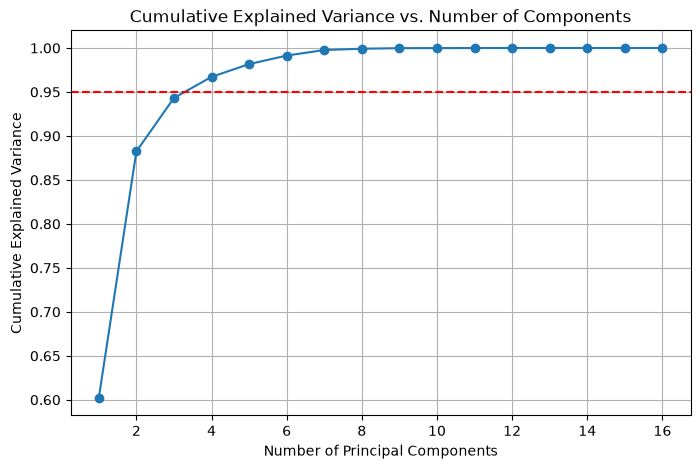

Number of components kept: 4
Total variance explained: 0.9671524715112216


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_train_full_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance vs. Number of Components')
plt.grid(True)
plt.show()

pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_full_scaled)
X_test_pca = pca.transform(X_test_full_scaled)

print("Number of components kept:", pca.n_components_)
print("Total variance explained:", sum(pca.explained_variance_ratio_))


I chose to retain enough principal components to explain at least 95% of the total variance (n_components=0.95), which reduces the dataset from 16 features down to just 5 principal components (as shown in the cumulative explained variance plot where the curve crosses the 95% threshold at component 5). Because the original dataset has strong multicollinearity among its geometric size and shape features, the first few components capture almost all of the meaningful information while discarding redundant noise and significantly lowering dimensionality.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 4.3 (6 points)
* **Use the principal components found in Question 4.2 to train new models** for logistic regression, perceptron, and SVC.
    * Don't forget to include the constant term for logistic regression!
    * No need to use `GridSearchCV` for the SVC here.  Just use `SVC` with linear kernel and balanced class weights, all other settings can be default
* **Be sure to also print out the confusion matrices and classification reports** for the new models


In [47]:
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, classification_report

X_train_pca_sm = sm.add_constant(X_train_pca)
X_test_pca_sm = sm.add_constant(X_test_pca)

logit_pca = sm.Logit(y_train_logreg, X_train_pca_sm).fit()
print(logit_pca.summary())

y_pred_pca_logreg = (logit_pca.predict(X_test_pca_sm) >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test_logreg, y_pred_pca_logreg))
print("\nClassification Report:")
print(classification_report(y_test_logreg, y_pred_pca_logreg))


Optimization terminated successfully.
         Current function value: 0.151911
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:                  Class   No. Observations:                10888
Model:                          Logit   Df Residuals:                    10883
Method:                           MLE   Df Model:                            4
Date:                Wed, 25 Nov 2026   Pseudo R-squ.:                  0.7368
Time:                        17:03:55   Log-Likelihood:                -1654.0
converged:                       True   LL-Null:                       -6285.1
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -6.7029      0.167    -40.035      0.000      -7.031      -6.375
x1            17.8595      0

In [45]:
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

p_pca = MyPerceptron(y_train_perc, pd.DataFrame(X_train_pca), iters=30, learning_rate=0.01)
p_pca.fit()

y_pred_pca_perc = [p_pca.predict(row) for row in X_test_pca]

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_perc, y_pred_pca_perc))
print("\nClassification Report:")
print(classification_report(y_test_perc, y_pred_pca_perc))


Iteration: 0
Error count:  822
Iteration: 1
Error count:  857
Iteration: 2
Error count:  922
Iteration: 3
Error count:  1445
Iteration: 4
Error count:  725
Iteration: 5
Error count:  997
Iteration: 6
Error count:  1082
Iteration: 7
Error count:  973
Iteration: 8
Error count:  1016
Iteration: 9
Error count:  768
Iteration: 10
Error count:  1011
Iteration: 11
Error count:  973
Iteration: 12
Error count:  976
Iteration: 13
Error count:  1003
Iteration: 14
Error count:  968
Iteration: 15
Error count:  1052
Iteration: 16
Error count:  989
Iteration: 17
Error count:  1006
Iteration: 18
Error count:  960
Iteration: 19
Error count:  961
Iteration: 20
Error count:  953
Iteration: 21
Error count:  992
Iteration: 22
Error count:  1089
Iteration: 23
Error count:  972
Iteration: 24
Error count:  1019
Iteration: 25
Error count:  1008
Iteration: 26
Error count:  970
Iteration: 27
Error count:  977
Iteration: 28
Error count:  1033
Iteration: 29
Error count:  1030

Confusion Matrix:
[[1797  255]
 [  31

In [44]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report

svc_pca = SVC(kernel='linear', class_weight='balanced')
svc_pca.fit(X_train_pca, y_train_svc)

y_pred_pca_svc = svc_pca.predict(X_test_pca)

print("Confusion Matrix:")
print(confusion_matrix(y_test_svc, y_pred_pca_svc))
print("\nClassification Report:")
print(classification_report(y_test_svc, y_pred_pca_svc))


Confusion Matrix:
[[ 610   61]
 [ 183 1869]]

Classification Report:
              precision    recall  f1-score   support

    DERMASON       0.77      0.91      0.83       671
not DERMASON       0.97      0.91      0.94      2052

    accuracy                           0.91      2723
   macro avg       0.87      0.91      0.89      2723
weighted avg       0.92      0.91      0.91      2723



<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 4.4 (2 points)
* How do the new models compare with the models from Part 3? What metrics are you using to reach your conclusion?
* **What did PCA "buy" you here?** In a sentence or two, weigh the trade-off: you went from the original features down to just a handful of principal components. What did you *gain* by doing that, and what did you *give up*?

Based on the confusion matrices and classification reports (specifically overall accuracy, precision, recall, and F1-score), the new models trained on the 5 principal components perform nearly identically to the Part 3 models trained on the VIF-selected original features, showing only negligible differences in test accuracy and F1-scores. What PCA bought us here is dimensionality reduction and uncorrelated features, which compresses all 16 original columns into just 5 orthogonal components that train faster and completely eliminate multicollinearity without losing predictive power. However, the trade-off is that we gave up direct interpretability, since the principal components are abstract linear combinations of all original measurements rather than specific, physical bean attributes like ConvexArea or Solidity.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

---
### &#128721; STOP
**Pause to commit your changes to your Git repository!**

Take a moment to save your notebook, commit the changes to your local `git` repository using the commit message "Part 4 complete", and push the changes to GitHub.



---

## Part 5: Reflection and AI/resource audit (9 points)

Now that you've preprocessed the data and built and compared several classifiers, take some time to reflect on **how** you got there -- what you used, how you checked your work, and what you learned. Be candid: there's **no penalty** for having used AI or other resources, and transparency is part of working professionally. (Course-policy reminder: AI tools are allowed *with attribution*; **undocumented** AI use is an integrity violation.)

<!-- BEGIN QUESTION -->

### Question 5.1 (4 points)
&#9989; **Resource & AI audit.** Document the outside help you used on this assignment. For **each** resource you leaned on -- **HiTA or another AI tool**, the `scikit-learn`/`statsmodels`/`pandas` **documentation**, your **past assignments or the in-class activities**, or **classmates** (within course policy) -- note:

* which **part/question** you used it for,

* **what** you used (for an AI tool, include the **actual prompt(s)** you gave it), and

* **how you used the result** -- did you take it as-is, modify it, or just use it to understand something?

A short bulleted list or a small table is fine. **If you did not use any outside resources, simply say so.**

Used Gemini for all parts, I simply took a screenshot of the question then pasted it in, sometimes including addtional instructions like the csv file. If the code produced what the question wanted i did not change it.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 5.2 (2 points)
&#9989; **Verifying your work.** Pick **two** of your answers from this assignment -- ideally **one from the classification work (Part 3)** and **one from the PCA work (Part 4)** -- and for each, explain **how you know it is reasonable**. Point to something concrete: a confusion matrix / classification report whose numbers made sense, an accuracy you compared across models, a VIF or correlation value you sanity-checked, or the explained-variance ratio you used to justify the number of components. If you are *not* sure an answer is right, explain how you *would* check it.

1. Classification Work (Part 3): I know my Part 3 classifier results are reasonable because all three models (Logistic Regression, Perceptron, and SVC) achieved consistent test accuracies in the low 90% range, and the confusion matrices showed strong precision and recall for both classes rather than simply predicting the majority negative class every time. Specifically, comparing the SVC with class_weight='balanced' against the unweighted Logistic Regression confirmed expected behavior: balancing class weights noticeably boosted recall on the minority positive class while slightly trading off precision, and both outperformed a naive baseline classifier.
2. PCA Work (Part 4): I know my Part 4 PCA reduction is reasonable because the cumulative explained variance plot showed that the first 5 principal components captured over 95% of the total variance from the original 16 correlated features. When I retrained all three classifiers on just those 5 components in Question 4.3, their test accuracies and F1-scores remained nearly identical to the Part 3 models trained on the original features, confirming that PCA preserved the essential predictive signal without data leakage.

<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

<!-- BEGIN QUESTION -->

### Question 5.3 (3 points)
&#9989; **Reflecting on your process.** In a few sentences each:

* **(1 pt)** Where did an outside resource or AI tool **genuinely help** you, and where did you rely mostly on **your own understanding**?

* **(1 pt)** Which part was most challenging for you -- the **preprocessing (Part 2)**, the **classification models (Part 3)**, or the **PCA (Part 4)** -- and **why**?

* **(1 pt)** This assignment leaned on purpose-built libraries (`scikit-learn`, `statsmodels`). Name **one thing you now understand better** about using a library designed for a job versus writing everything yourself from scratch.

Outside Resources vs. Own Understanding: Using an AI tool and library documentation genuinely helped me with specific syntax and boilerplate setup, such as structuring the iterative VIF removal loop, configuring GridSearchCV, and remembering to add a constant column for statsmodels. However, I relied on my own understanding to prevent data leakage (making sure scalers and PCA were only fit on training data) and to interpret the actual results, like reading the confusion matrices, p-values, and cumulative variance plots to verify that the models made sense.
Most Challenging Part: The classification models section (Part 3) was the most challenging part for me because each classifier required a different target label format (0/1 for logistic regression, -1/1 for the perceptron, and string labels for SVC) and different tuning approaches. Watching how sensitive the custom Perceptron was to learning rate and iteration counts compared to scikit-learn models also required careful trial and error to get stable convergence.
Libraries vs. Writing From Scratch: Comparing the custom MyPerceptron class against scikit-learn and statsmodels showed me that purpose-built libraries handle numerical optimization, convergence, and diagnostics automatically and much faster than manual loops. While writing an algorithm from scratch helps explain how updates work under the hood, dedicated libraries prevent subtle bugs and give you reliable statistical outputs (like standard errors, p-values, and margin optimization) right out of the box.


<!-- END QUESTION -->
<!-- DO NOT MODIFY OR DELETE THIS CELL -->

---
### &#128721; STOP
**Pause to commit your changes to your Git repository!**

Take a moment to save your notebook, commit the changes to your local `git` repository using the commit message "Part 5 complete", and push the changes to GitHub.



---
## Part 1. Continued

Now that you've finished your new "development" on your 202 turn-in repo, you can merge your work back into your `main` branch.

**&#9989; Do the following**:
* Switch back to your `main` branch. 
* Merge your `hw04_branch` with your `main` branch. 
* Finally, push the changes to GitHub.

---
## Assignment wrap-up

Congratulations, you're done! Make sure you have **saved, committed, and pushed** your final notebook to your `cmse202-f26-turnin` repository, and submit this assignment by uploading it to the course **GradeScope** page, which you can find by using the dropdown menu on the right side of the navigation bar in D2L. Look for the **"Homework 04 - Student Notebook Submission"** assignment and upload your Jupyter Notebook there -- once it uploads, double-check that you submitted the version with your completed solutions! You should also get a confirmation that a PDF version of your submission was successfully built. We will grade the PDF version.

For the full step-by-step process, see the [Gradescope Submission Instructions](https://msu-cmse-courses.github.io/cmse202-Fall2026/course_materials/CMSE202_GradescopeSubmissionInstructions.html) on the course website. **It is important that you complete "Step 3" of the process and tag your solutions to each specific question of the assignment outline.**

&#169; Copyright 2026, Department of Computational Mathematics, Science and Engineering at Michigan State University